In [1]:
import numpy as np
import matplotlib.pyplot as plt
from train_universal.predict_uni import plot_Battery_uni


def show_discharge_charge(**kw):
    """同一设计点的放电 + 充电曲线画到一张图（充电用镜像法，共用放电网络）。

    plot_Battery_uni(plot=False) 两次调用：放电（满电 x0 出发）+ 充电
    （mode='charge'，0% SOC stoi0 出发，到上截止电压 V_cutoff 截断）。
    返回 (放电 dict, 充电 dict)，含 t / V / 表面化学计量比 / design 等。
    """
    rd = plot_Battery_uni(plot=False, **kw)
    rc = plot_Battery_uni(plot=False, mode='charge', **kw)
    if rd is None or rc is None:
        return rd, rc
    d = rd['design']
    plt.figure(figsize=(8, 4.8))
    v_end_d = rd['V'][np.isfinite(rd['V'])][-1]
    plt.plot(rd['t'], rd['V'], '-', lw=1.6, color='tab:blue',
             label='discharge %.2f -> %.2f V' % (rd['V'][0], v_end_d))
    lab = 'charge %.2f -> %.2f V' % (rc['V'][0], rc['V'][np.isfinite(rc['V'])][-1])
    if rc['cutoff_reached']:
        lab += ' (cutoff %.1f V @ %.0f s)' % (rc['V_cutoff'], rc['t_cutoff'])
    plt.plot(rc['t'], rc['V'], '-', lw=1.6, color='tab:red', label=lab)
    plt.axhline(rc['V_cutoff'], color='gray', ls=':', lw=0.8)
    plt.xlabel('t [s]')
    plt.ylabel('V [V]')
    plt.title('L_n=%.0f um  L_p=%.0f um  eps_n=%.2f  eps_p=%.2f  C=%.1fC\n'
              'R_s,n=%.1f um  R_s,p=%.1f um  D_s,n=%.1e  D_s,p=%.1e m2/s  (limiting: %s)'
              % (d['thickness_n'] * 1e6, d['thickness_p'] * 1e6,
                 d['porosity_n'], d['porosity_p'], d['C_rate'],
                 d['R_s_n'] * 1e6, d['R_s_p'] * 1e6, d['D_s_n'], d['D_s_p'],
                 rd['limiting']), fontsize=9)
    plt.legend(fontsize=9, loc='lower left')
    plt.tight_layout()
    print('discharge: %.3f -> %.3f V | charge: %.3f -> %.3f V%s'
          % (rd['V'][0], v_end_d, rc['V'][0], rc['V'][np.isfinite(rc['V'])][-1],
             (', %.0f s to %.1f V' % (rc['t_cutoff'], rc['V_cutoff']))
             if rc['cutoff_reached'] else ''))
    return rd, rc


## 万能族 PINN：充放电曲线

- `plot_Battery_uni(...)`：恒流**放电**，从满电均匀初值 `x0` 出发；
- `mode='charge'`：恒流**充电**——PDE、常通量 BC、均匀初值均线性，充电解是放电解的
  **镜像**（网络偏移取反，`x = stoi0 − u`），**共用同一网络、零重训**；从 0% SOC
  （`stoi0`）出发，到上截止电压 `V_cutoff`（默认 4.2 V）截断，只覆盖 CC 恒流段；
- `R_s_n/p`（颗粒半径）、`D_s_n/p`（扩散系数）是万能族解锁的自由参数，
  未提供的参数自动用默认电芯（NMC811 / Gr-Si，110/70 µm，孔隙率 0.56/0.31）。


discharge: 3.947 -> 2.275 V | charge: 3.186 -> 4.206 V, 3683 s to 4.2 V


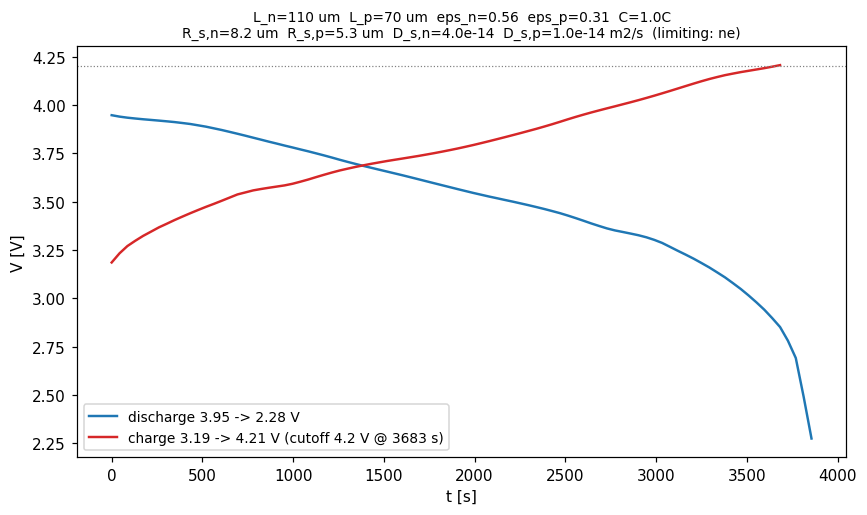

In [3]:
rd, rc = show_discharge_charge()                 # 全默认 -> 参考电芯 1C 充放电曲线


discharge: 3.816 -> 2.459 V | charge: 3.493 -> 4.205 V, 1257 s to 4.2 V


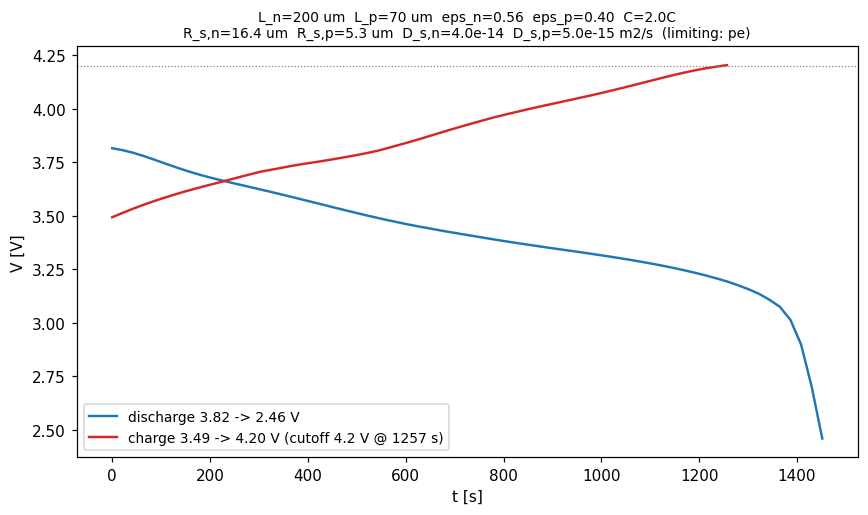

In [4]:
rd, rc = show_discharge_charge(thickness_n=200e-6,
                               thickness_p=70e-6,
                               porosity_n=0.56,
                               porosity_p=0.4,
                               C_rate=2,
                               R_s_n=1.64e-5,
                               R_s_p=5.3e-6,
                               D_s_n=4e-14,
                               D_s_p=5e-15)


discharge: 3.815 -> 2.649 V | charge: 3.495 -> 4.207 V, 1257 s to 4.2 V


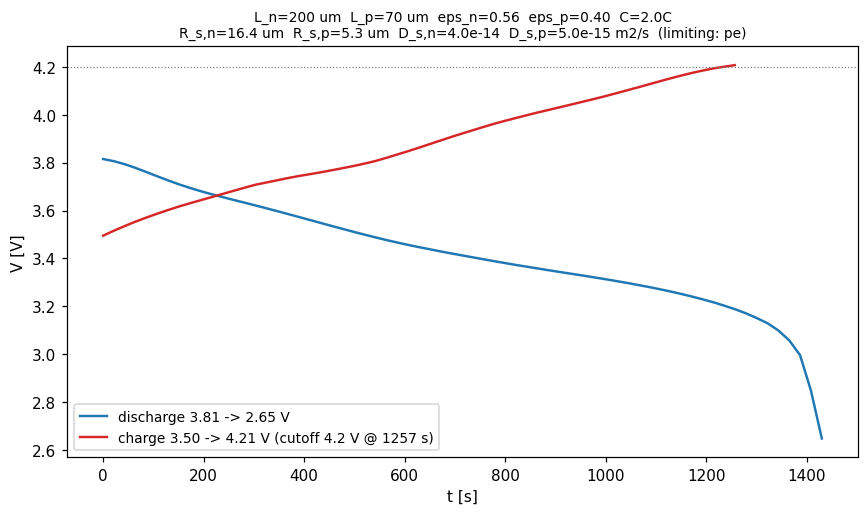

In [5]:
rd, rc = show_discharge_charge(thickness_n=200e-6,   # 任意组合，未给的自动补默认
                               porosity_p=0.4,
                               C_rate=2,
                               R_s_n=1.64e-5,        # 颗粒半径：新解锁的自由参数
                               D_s_p=5e-15)          # 扩散系数：同上
